# EDA Sprint 2 – Equipo 3 – PP1 Economía del Conocimiento – 2C 2026

Gráficos e indicadores del documento **PP1-S2-EDA-Sprint2.docx**, calculados sobre los archivos limpios de `data/processed`.

**Cómo usarlo**
- **Desde el repo:** se ejecuta directo (lee `../data/processed/`).
- **En Google Colab:** en el panel de la izquierda (ícono de carpeta 📁 → ⬆) subí estos 4 archivos y después *Entorno de ejecución → Ejecutar todas*:
  - `sysarmy_limpio.csv`
  - `programas_limpio.csv`
  - `empleo_provincia_limpio.csv`
  - `mapa_provincias.csv`

Los gráficos se guardan como PNG en la misma carpeta.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def buscar(nombre):
    # Busca el archivo en el repo o en la carpeta de Colab
    for carpeta in ['../data/processed', 'data/processed', '.', '/content']:
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    raise FileNotFoundError(f'No encuentro {nombre}: subilo al panel de archivos de Colab')

sysarmy  = pd.read_csv(buscar('sysarmy_limpio.csv'))
programas = pd.read_csv(buscar('programas_limpio.csv'))
empleo   = pd.read_csv(buscar('empleo_provincia_limpio.csv'))
mapa     = pd.read_csv(buscar('mapa_provincias.csv')).drop_duplicates('provincia_id')
nombre_prov = mapa.set_index('provincia_id')['provincia']

print('Sysarmy:', sysarmy.shape, '| Programas:', programas.shape, '| Empleo:', empleo.shape, '| Provincias:', len(mapa))

Sysarmy: (4939, 15) | Programas: (1035, 8) | Empleo: (20115, 5) | Provincias: 24


In [2]:
# Estilo común de los gráficos
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 10})
AZUL, NARANJA, NEGRO, GRIS = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'
SENIORITY = ['Junior', 'Semi-Senior', 'Senior']

def millones(v):
    return f'{v/1e6:.2f}'.replace('.', ',')

## 1. Controles de calidad después del ETL

In [3]:
print('Nulos en campos clave')
print(' Sysarmy:', sysarmy[['provincia_id','salario_bruto','seniority','grupo_puesto']].isna().sum().sum())
print(' Programas:', programas[['programa','provincia_id','anio','monto']].isna().sum().sum())
print('Id repetidos  Sysarmy:', sysarmy.id_respuesta.duplicated().sum(), '| Programas:', programas.id_beneficio.duplicated().sum())
print(f'Monto total programas: ${programas.monto.sum():,.2f}')
print('Empleo rama 62 por año:')
print(empleo[empleo.clae2 == 62].groupby('anio').puestos_promedio.sum().round(1))

Nulos en campos clave
 Sysarmy: 0
 Programas: 0
Id repetidos  Sysarmy: 0 | Programas: 0
Monto total programas: $7,132,754,692.09
Empleo rama 62 por año:
anio
2014     82224.4
2015     85447.0
2016     88373.2
2017     92726.0
2018     98247.4
2019    105764.7
2020    110916.6
2021    121759.0
2022    133663.4
2023    137172.6
Name: puestos_promedio, dtype: float64


## 2. Pregunta 1 – Salarios de Datos e IA frente al resto de IT

Solo Full-Time. Se compara **dentro de cada seniority**, porque los grupos tienen composiciones distintas.

In [4]:
ft = sysarmy[sysarmy.dedicacion == 'Full-Time']
mediana = ft.groupby(['seniority', 'grupo_puesto']).salario_bruto.median().unstack().loc[SENIORITY]
tabla = mediana.copy()
tabla['Diferencia %'] = (tabla['Datos e IA'] / tabla['Resto IT'] - 1) * 100
total = ft.groupby('grupo_puesto').salario_bruto.median()
print(tabla.round(1))
print(f"Total: Datos e IA {total['Datos e IA']:,.0f} | Resto IT {total['Resto IT']:,.0f} | diferencia {(total['Datos e IA']/total['Resto IT']-1)*100:.1f} %")

grupo_puesto  Datos e IA   Resto IT  Diferencia %
seniority                                        
Junior         2100000.0  1737059.0          20.9
Semi-Senior    3068000.0  2650000.0          15.8
Senior         4200000.0  4195584.0           0.1
Total: Datos e IA 3,100,000 | Resto IT 3,399,083 | diferencia -8.8 %


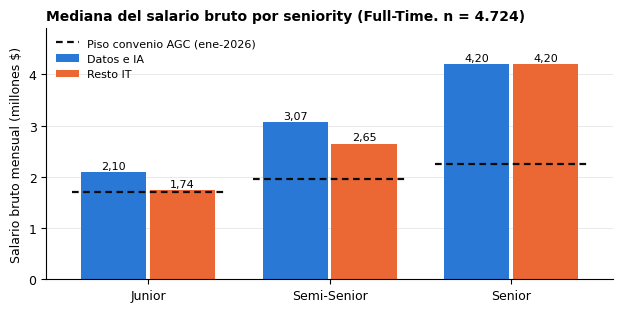

In [5]:
# Gráfico 1: mediana por seniority y piso del convenio AGC (enero 2026)
piso_agc = [1709393, 1965803, 2260673]
fig, ax = plt.subplots(figsize=(6.3, 3.2)); x = range(3); w = .36
b1 = ax.bar([i - w/2 - .01 for i in x], mediana['Datos e IA'], w, color=AZUL, label='Datos e IA')
b2 = ax.bar([i + w/2 + .01 for i in x], mediana['Resto IT'], w, color=NARANJA, label='Resto IT')
for i, v in enumerate(piso_agc):
    ax.hlines(v, i - w - .06, i + w + .06, color=NEGRO, lw=1.6, ls=(0, (3, 2)),
              label='Piso convenio AGC (ene-2026)' if i == 0 else None)
for barras in (b1, b2):
    for r in barras:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 6e4, millones(r.get_height()), ha='center', fontsize=8)
ax.set_xticks(list(x)); ax.set_xticklabels(SENIORITY); ax.set_ylabel('Salario bruto mensual (millones $)')
ax.yaxis.set_major_formatter(lambda v, _: f'{v/1e6:.0f}'); ax.set_ylim(0, 4.9e6)
ax.grid(axis='y', color='#e6e5e0', lw=.6); ax.set_axisbelow(True)
ax.set_title(f'Mediana del salario bruto por seniority (Full-Time, n = {len(ft):,})'.replace(',', '.'), loc='left')
ax.legend(frameon=False, fontsize=8, loc='upper left')
plt.tight_layout(); plt.savefig('g1_salarios_seniority.png', dpi=200); plt.show()

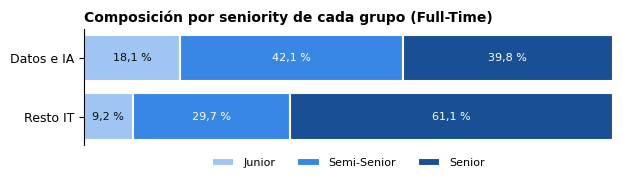

In [6]:
# Gráfico 2: composición por seniority (efecto composición)
comp = pd.crosstab(ft.grupo_puesto, ft.seniority, normalize='index')[SENIORITY] * 100
fig, ax = plt.subplots(figsize=(6.3, 1.9)); colores = ['#9ec5f4', '#3987e5', '#184f95']; izq = [0, 0]
for j, s in enumerate(SENIORITY):
    v = comp[s].values
    ax.barh(comp.index, v, left=izq, color=colores[j], label=s, edgecolor='white', lw=1.5)
    for i in range(2):
        ax.text(izq[i] + v[i]/2, i, f'{v[i]:.1f} %'.replace('.', ','), ha='center', va='center',
                fontsize=8, color='white' if j else NEGRO)
    izq = [izq[i] + v[i] for i in range(2)]
ax.set_xlim(0, 100); ax.set_xticks([]); ax.spines['bottom'].set_visible(False); ax.invert_yaxis()
ax.set_title('Composición por seniority de cada grupo (Full-Time)', loc='left')
ax.legend(ncol=3, frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.02))
plt.tight_layout(); plt.savefig('g2_composicion_seniority.png', dpi=200); plt.show()

## 3. Pregunta 2 – Fondos por provincia (indicadores relativos)

Los totales reflejan el tamaño de cada provincia, por eso se mira el **monto típico por beneficio**. Se excluye Capacitación 4.0 (beneficios chicos a municipios) y se muestran solo provincias con 5 o más beneficios.

Mediana país: $10.0 M | El 10 % de beneficios más grandes reúne el 41 % del dinero


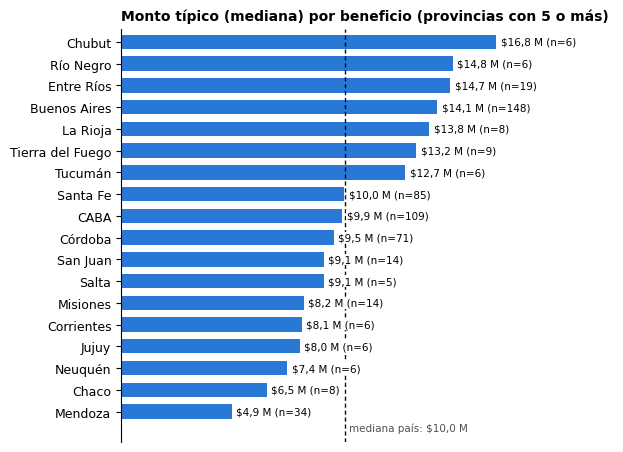

In [7]:
sin_cap = programas[programas.programa != 'Capacitacion 4.0']
tipico = sin_cap.groupby('provincia_id').monto.median() / 1e6
cantidad = sin_cap.groupby('provincia_id').size()
tipico.index = tipico.index.map(nombre_prov); cantidad.index = cantidad.index.map(nombre_prov)
tipico = tipico[cantidad[tipico.index] >= 5].sort_values()
mediana_pais = sin_cap.monto.median() / 1e6

# Concentración: cuánto dinero reúne el 10 % de beneficios de mayor monto
montos = programas.monto.sort_values(ascending=False)
top10 = montos.head(round(len(montos) * .1)).sum() / montos.sum() * 100
print(f'Mediana país: ${mediana_pais:.1f} M | El 10 % de beneficios más grandes reúne el {top10:.0f} % del dinero')

fig, ax = plt.subplots(figsize=(6.3, 4.6))
ax.barh(tipico.index, tipico.values, color=AZUL, height=.66)
ax.axvline(mediana_pais, color=NEGRO, lw=1, ls=(0, (3, 2)))
ax.text(mediana_pais + .2, -0.9, f'mediana país: ${mediana_pais:.1f} M'.replace('.', ','), fontsize=7.5, color=GRIS)
for i, (prov, v) in enumerate(tipico.items()):
    ax.text(v + .2, i, f'${v:.1f} M (n={cantidad[prov]})'.replace('.', ','), va='center', fontsize=7.5,
            bbox=dict(fc='white', ec='none', pad=.6))
ax.set_xticks([]); ax.spines['bottom'].set_visible(False); ax.set_xlim(0, 22); ax.set_ylim(-1.4, len(tipico) - .4)
ax.set_title('Monto típico (mediana) por beneficio (provincias con 5 o más)', loc='left')
plt.tight_layout(); plt.savefig('g3_monto_tipico.png', dpi=200); plt.show()

## 4. Pregunta 3 – Fondos y empleo informático

**Índice fondos / empleo** = % de los fondos de la provincia ÷ % del empleo de la rama 62 (2020–2023, sin Capacitación 4.0).
Si vale 1, la provincia recibe fondos en la misma proporción que su empleo. Es una comparación descriptiva: no busca causas.

In [8]:
fondos = sin_cap.groupby('provincia_id').monto.sum()
puestos = empleo[(empleo.clae2 == 62) & empleo.anio.between(2020, 2023)].groupby('provincia_id').puestos_promedio.sum()
p3 = pd.DataFrame({'% fondos': fondos / fondos.sum() * 100, '% empleo': puestos / puestos.sum() * 100})
p3['indice'] = p3['% fondos'] / p3['% empleo']
p3['fondos por puesto (por año)'] = fondos / (puestos / 4)
p3.index = p3.index.map(nombre_prov)
print(p3.sort_values('indice', ascending=False).round(2))
print('Provincias con índice mayor que 1:', (p3.indice > 1).sum(), 'de', len(p3))

                     % fondos  % empleo  indice  fondos por puesto (por año)
provincia_id                                                                
Tierra del Fuego         2.02      0.14   14.38                    789050.88
Formosa                  1.04      0.09   12.08                    663025.88
La Rioja                 2.00      0.19   10.55                    578778.58
Catamarca                0.85      0.09    9.14                    501609.31
San Juan                 2.42      0.37    6.59                    361510.37
Misiones                 2.35      0.38    6.23                    341594.26
Entre Ríos               4.47      0.98    4.55                    249400.47
Chubut                   1.38      0.36    3.83                    209983.59
Jujuy                    1.02      0.30    3.39                    186222.57
La Pampa                 0.54      0.19    2.82                    154489.48
Santa Fe                13.27      5.00    2.65                    145650.70

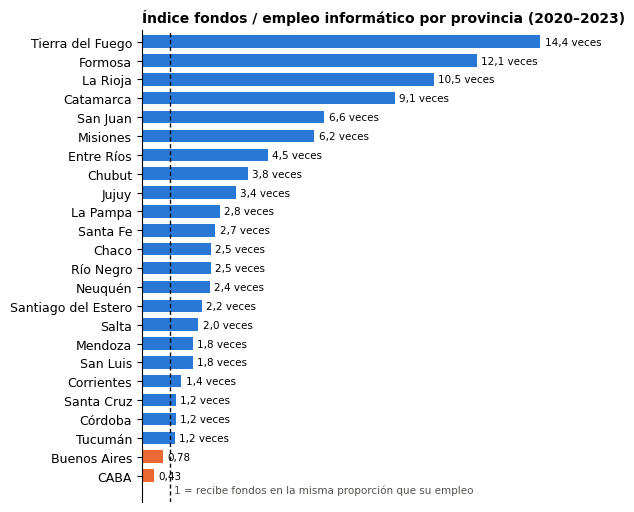

In [9]:
# Gráfico 4: índice fondos / empleo
k = p3.indice.sort_values()
fig, ax = plt.subplots(figsize=(6.3, 5.2))
ax.barh(k.index, k.values, color=[NARANJA if v < 1 else AZUL for v in k.values], height=.66)
ax.axvline(1, color=NEGRO, lw=1, ls=(0, (3, 2)))
ax.text(1.15, -0.9, '1 = recibe fondos en la misma proporción que su empleo', fontsize=7.5, color=GRIS)
for i, v in enumerate(k.values):
    etiqueta = f'{v:.1f} veces' if v >= 1 else f'{v:.2f}'
    ax.text(v + .15, i, etiqueta.replace('.', ','), va='center', fontsize=7.5)
ax.set_xticks([]); ax.spines['bottom'].set_visible(False); ax.set_xlim(0, 17); ax.set_ylim(-1.4, len(k) - .4)
ax.set_title('Índice fondos / empleo informático por provincia (2020–2023)', loc='left')
plt.tight_layout(); plt.savefig('g4_indice_fondos_empleo.png', dpi=200); plt.show()